# Taller 1 · ¿Hasta dónde sirve el modelo del balancín?

**Control Inteligente II (168418) · Universidad de Pamplona**
Docente: Ing. Jeisson Martínez Flórez · Viernes 23 de octubre de 2026

---

Actividad **formativa**, sin nota. Trabaje con su equipo de proyecto.

**Qué va a hacer.** Va a simular el robot balancín que construyeron este semestre. Va a medir en cuánto
tiempo se cae sin control, va a encontrar el polo inestable de la planta y va a determinar hasta qué
ángulo el *modelo linealizado* sigue siendo válido. Esos tres números son importantes para el resto de temas que vamos a ver.

**Requisitos.** Solo `numpy` y `matplotlib`. Si no tiene Python instalado, abra el cuaderno en Google
Colab (Archivo → Subir cuaderno) y ejecútelo allí sin instalar nada.

**Entregable de la actividad.** La tabla del paso 5 diligenciada y las tres respuestas del paso 6, en
este mismo cuaderno. Se comparte por el grupo de WhatsApp.

---
## 0. El modelo

Coordenadas: `x` es la posición del eje de las ruedas y `th` (θ) la inclinación del cuerpo respecto
a la vertical. θ = 0 es el robot en pie. La entrada es el par total `tau` que los motores aplican
entre las ruedas y el cuerpo.

Ecuaciones de Lagrange del péndulo invertido de dos ruedas, plano y sin deslizamiento:

$$A\,\ddot{x} + B\cos\theta\,\ddot{\theta} - B\sin\theta\,\dot{\theta}^2 = \frac{\tau}{r}$$

$$C\,\ddot{\theta} + B\cos\theta\,\ddot{x} - Bg\sin\theta = -\tau$$

con

$$A = 2m_w + \frac{2I_w}{r^2} + M_b \qquad B = M_b\,\ell \qquad C = I_b + M_b\,\ell^2$$

Ejecute la celda siguiente sin cambiar nada.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 9.81  # m/s^2

# --- Datos medidos del balancin del equipo ---
mw  = 0.050    # masa de UNA rueda [kg]: 50 g medidos
r   = 0.033    # radio de rueda [m]: 33 mm medidos
Mb  = 0.750    # masa del cuerpo inclinable [kg]: 750 g medidos
l   = 0.062    # eje de ruedas al centro de masa [m]: 6.2 cm medidos

# IMPORTANTE: Ib aun NO se ha medido.
# Se conserva 1e-3 kg m^2 solo como valor provisional para poder ejecutar
# las simulaciones. Los resultados que dependen de Ib son provisionales.
# Reemplazar cuando se mida o estime la distribucion de masa del cuerpo.
Ib  = 1.0e-3   # valor PROVISIONAL, no es una medicion del robot

# Aproximacion: cada rueda es un disco macizo homogeneo.
Iw = 0.5 * mw * r**2

print('DATOS DEL ROBOT')
print(f'Mb = {Mb:.3f} kg; l = {l:.3f} m; mw = {mw:.3f} kg; r = {r:.3f} m')
print(f'Iw estimado por rueda = {Iw:.6e} kg·m²')
print(f'Ib provisional = {Ib:.6e} kg·m² (actualizar al medirlo)')

def coeficientes(Mb=Mb, mw=mw, r=r, l=l, Ib=Ib):
    Iw = 0.5 * mw * r**2
    A = 2*mw + 2*Iw/r**2 + Mb
    B = Mb * l
    C = Ib + Mb * l**2
    return A, B, C, A*C - B**2

A, B, C, D = coeficientes()
print(f"\nA = {A:.4f} kg      B = {B:.5f} kg·m")
print(f"C = {C:.3e} kg·m²   D = AC - B² = {D:.3e}")


DATOS DEL ROBOT
Mb = 0.750 kg; l = 0.062 m; mw = 0.050 kg; r = 0.033 m
Iw estimado por rueda = 2.722500e-05 kg·m²
Ib provisional = 1.000000e-03 kg·m² (actualizar al medirlo)

A = 0.9000 kg      B = 0.04650 kg·m
C = 3.883e-03 kg·m²   D = AC - B² = 1.332e-03


### Datos reales del equipo y parámetro pendiente

Se actualizaron los parámetros medidos:

- Masa del cuerpo inclinable: **750 g = 0.750 kg**.
- Distancia del eje de ruedas al centro de masa: **6.2 cm = 0.062 m**.
- Masa de una rueda: **50 g = 0.050 kg**.
- Radio de rueda: **33 mm = 0.033 m**.

La inercia de una rueda se aproxima como disco macizo: \(I_w=\frac12m_wr^2=2.7225\times10^{-5}\;\text{kg·m}^2\). Es una estimación, porque la rueda real puede tener radios, huecos o masa concentrada en el borde.

**Falta medir o estimar \(I_b\)**, el momento de inercia del cuerpo respecto a su propio centro de masa. Por ahora el código conserva \(I_b=0.001\;\text{kg·m}^2\) únicamente como valor provisional heredado del ejemplo; no debe presentarse como una medición real. Los resultados de simulación, polo y tiempo de caída que dependen de este parámetro también son provisionales hasta actualizarlo.

Para estimar \(I_b\) mejor, se puede: (1) listar la masa y ubicación de cada componente y sumar sus inercias con el teorema de ejes paralelos, o (2) medir el periodo de oscilación pequeña del cuerpo alrededor del eje de las ruedas, con el cuerpo en configuración de péndulo estable y desacoplado de motores/control, para estimar la inercia total respecto al eje y luego restar \(M_b l^2\). Debe hacerse con el montaje seguro y sin energizar motores.


---
## 1. El modelo no lineal y el integrador

`f_nolineal` despeja las dos aceleraciones resolviendo el sistema 2×2 de arriba. `rk4` es un
integrador de Runge-Kutta de cuarto orden.
> Este método es usado para resolver ecuaciones diferenciales ordinarias con un valor inicial dado. En el modelo del balancín, las ecuaciones de movimiento se expresan como ecuaciones diferenciales complejas (en `f_nolineal`) el integrador Runge-Kutta toma el estado actual del robot (posición, velocidad, ángulo, velocidad angular) y avanza en el tiempo en pequeños pasos (h). Para cada paso, calcula la "pendiente" o derivada en varios puntos intermedios (k1, k2, k3, k4) y toma un promedio ponderado para estimar cuál será el estado del robot en el siguiente instante (hacia donde va). Así se puede "simular" fácilmente la física del robot a lo largo del tiempo.

Ejecute la celda y observe la forma de la caída.

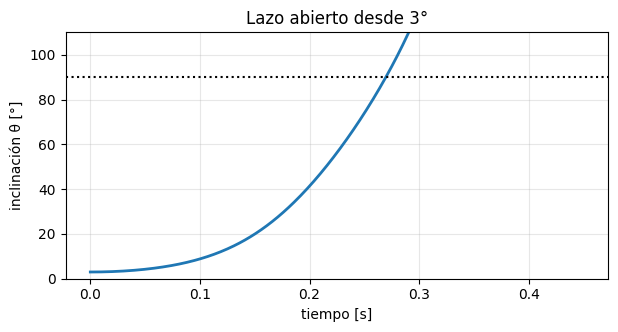

In [2]:
def f_nolineal(s, tau=0.0, Mb=Mb):
    """s = [x, xdot, th, thdot]  ->  derivada del estado."""
    A, B, C, _ = coeficientes(Mb=Mb)        # Obtiene parámetros
    x, xd, th, thd = s                      # Desempaqueta el vector de estado
    ct, st = np.cos(th), np.sin(th)         # Calcula coseno y seno
    M = np.array([[A,    B*ct],             # Construye matriz de inercia
                  [B*ct, C   ]])
    b = np.array([tau/r + B*st*thd**2,      # Construye vector de fuerzas ext
                  -tau  + B*G*st])
    xdd, thdd = np.linalg.solve(M, b)       # Resuelve el sistema de EcuLineal
    return np.array([xd, xdd, thd, thdd])

def rk4(f, s0, t, **kw):                            # Parámetros de entrada: f=f_nolineal , s0=estado inicial, t=instantes de tiempo, **kw=argumentos extra
    s = np.zeros((len(t), len(s0))); s[0] = s0      # Prepara matriz para guardar estados del robot
    for k in range(len(t)-1):                       # Avance paso a paso
        h = t[k+1] - t[k]                           # Calcula tamaño del paso de tiempo actual
        k1 = f(s[k],          **kw)                 # Evalúa la derivada del vector de estado actual y subpasos
        k2 = f(s[k] + h/2*k1, **kw)
        k3 = f(s[k] + h/2*k2, **kw)
        k4 = f(s[k] + h*k3,   **kw)
        s[k+1] = s[k] + h/6*(k1 + 2*k2 + 2*k3 + k4) # Calcula el estado del robot en el siguiente instante de tiempo
    return s

# Vector de tiempo para la simulación | Deste 0->0.45 con 451 puntos
t = np.linspace(0, 0.45, 451)

''' Explicación de 's':
Ejecuta la simulación con las funciones rk4 y f_nolineal.
Argumentos:
- f_nolineal = que contiene el modelo del robot.
- [0, 0, np.radians(3), 0] = es el vector del estado inicial. Posición 0. Velocidad 0. Ángulo de 3 grados (en radianes). Velocidad angular 0.
- t = vector de tiempo.
'''
s = rk4(f_nolineal, [0, 0, np.radians(3), 0], t)

# Gráfico
plt.figure(figsize=(7, 3.2))
plt.plot(t, np.degrees(s[:, 2]), lw=2)                 # Curva azul de ángulo del robot según simulación
plt.axhline(90, ls=":", color="k")                     # Línea negra que indica 90º = robot cae al suelo
plt.xlabel("tiempo [s]"); plt.ylabel("inclinación θ [°]"); plt.ylim(0, 110)
plt.title("Lazo abierto desde 3°"); plt.grid(alpha=.3); plt.show()


### Paso 1 · Tiempo de caída

Complete la función. `t_caida` debe devolver el instante en el que θ llega a 90°, es decir, cuando
el robot ya está acostado.

In [3]:
def t_caida(th0_grados, Mb=Mb, t_max=1.0):
    t = np.linspace(0, t_max, 2001)
    s = rk4(f_nolineal, [0, 0, np.radians(th0_grados), 0], t, Mb=Mb)
    th = np.degrees(s[:, 2])
    # Busca el primer instante en que el ángulo alcanza o supera 90°.
    # flatnonzero devuelve los índices donde la condición es verdadera.
    indices = np.flatnonzero(th >= 90)
    if len(indices) == 0:
        return np.nan  # No cayó dentro de t_max segundos.
    k = indices[0]
    return t[k]

# Pruebe para diferentes ángulos iniciales
for th0 in [1, 3, 5]:
    print(f"θ0 = {th0}°  ->  cae en {1000*t_caida(th0):.0f} ms")

θ0 = 1°  ->  cae en 332 ms
θ0 = 3°  ->  cae en 270 ms
θ0 = 5°  ->  cae en 241 ms


---
## 2. El modelo linealizado

Alrededor de θ = 0, con θ pequeño y θ̇ ≈ 0, se toma sen θ ≈ θ, cos θ ≈ 1 y θ̇² ≈ 0. El sistema queda

$$\begin{bmatrix} A & B \\ B & C\end{bmatrix}
\begin{bmatrix}\ddot{x}\\ \ddot{\theta}\end{bmatrix}
= \begin{bmatrix}\tau/r \\ Bg\theta - \tau\end{bmatrix}$$

y despejando se llega al espacio de estados con $\mathbf{x} = [x,\ \dot{x},\ \theta,\ \dot{\theta}]^T$
y $u = \tau$.

### Paso 2 · Complete la matriz de estado

Los dos huecos son los términos que multiplican a θ en las filas de ẍ y de θ̈. Salen de resolver
el sistema de arriba con τ = 0, usando D = AC − B².

### ¿De dónde salen los dos coeficientes?
Con la entrada anulada (τ = 0) y usando la aproximación de ángulo pequeño, el sistema es `A*ẍ + B*θ̈ = 0` y `B*ẍ + C*θ̈ = B*g*θ`. Su matriz de masa es `[[A, B], [B, C]]`, cuyo determinante es `D = AC − B²`. Al invertirla, `ẍ = −(B²g/D)θ` y `θ̈ = (ABg/D)θ`. Por eso esos términos se ubican en la segunda y cuarta filas de la matriz de estado, respectivamente.


In [4]:
def espacio_estados(Mb=Mb):
    A, B, C, D = coeficientes(Mb=Mb)
    Am = np.array([[0, 1, 0,   0],
                   [0, 0, -B**2 * G / D, 0],  # ẍ = -(B²g/D) θ cuando τ = 0
                   [0, 0, 0,   1],
                   [0, 0, A*B * G / D, 0]])  # θ̈ = (ABg/D) θ cuando τ = 0
    Bm = np.array([0.0, (C/r + B)/D, 0.0, -(A + B/r)/D])
    return Am, Bm

Am, Bm = espacio_estados()
print("A =\n", np.round(Am, 3))
print("\nB =", np.round(Bm, 2))
print("\nvalores propios:", np.round(np.linalg.eigvals(Am), 3))

A =
 [[  0.      1.      0.      0.   ]
 [  0.      0.    -15.919   0.   ]
 [  0.      0.      0.      1.   ]
 [  0.      0.    308.116   0.   ]]

B = [    0.     123.21     0.   -1732.97]

valores propios: [  0.      0.     17.553 -17.553]


### Paso 3 · El polo inestable y el periodo de muestreo

El valor propio positivo `p` es el que hace caer al robot. Su inverso `1/p` es la constante de
tiempo de la caída.

Regla práctica de control digital: el lazo debe muestrear al menos **20 veces** dentro de una
constante de tiempo del modo más rápido de la planta.

Como la constante de tiempo es τc = 1/p, y se piden 20 muestras dentro de ella, el periodo máximo es Ts = τc/20 = 1/(20p). Para convertir segundos a milisegundos se multiplica por 1000.


In [5]:
p = max(np.linalg.eigvals(Am).real)
print(f"polo inestable        p    = +{p:.3f} rad/s")
print(f"constante de tiempo   1/p  = {1000/p:.1f} ms")

# Muestrear 20 veces por constante de tiempo: Ts <= (1/p)/20.
Ts_ms = 1000 / (20 * p)
print(f"periodo de muestreo   Ts  <= {Ts_ms:.2f} ms")

polo inestable        p    = +17.553 rad/s
constante de tiempo   1/p  = 57.0 ms
periodo de muestreo   Ts  <= 2.85 ms


---
## 3. ¿Hasta dónde sirve la linealización?

Con τ = 0 y θ̇ = 0, los dos modelos predicen aceleraciones angulares distintas:

$$\ddot{\theta}_{\text{no lineal}} = \frac{ABg\sin\theta}{AC - B^2\cos^2\theta}
\qquad
\ddot{\theta}_{\text{lineal}} = \frac{ABg\,\theta}{D}$$

### Paso 4 · Mida el error

In [6]:
def thdd_nolineal(th, Mb=Mb):
    A, B, C, _ = coeficientes(Mb=Mb)
    return A*B*G*np.sin(th) / (A*C - B**2*np.cos(th)**2)

def thdd_lineal(th, Mb=Mb):
    A, B, C, D = coeficientes(Mb=Mb)
    return A*B*G*th / D

def error_pct(th_grados):
    th = np.radians(th_grados)
    return 100*(thdd_lineal(th) - thdd_nolineal(th))/thdd_nolineal(th)

for d in [1, 2, 5, 10, 15, 20, 30, 45]:
    print(f"θ = {d:3d}°   error = {error_pct(d):6.2f} %")

θ =   1°   error =   0.05 %
θ =   2°   error =   0.22 %
θ =   5°   error =   1.36 %
θ =  10°   error =   5.43 %
θ =  15°   error =  12.15 %
θ =  20°   error =  21.43 %
θ =  30°   error =  47.20 %
θ =  45°   error = 101.19 %


5 %  de error a los 9.6°
10 % de error a los 13.6°


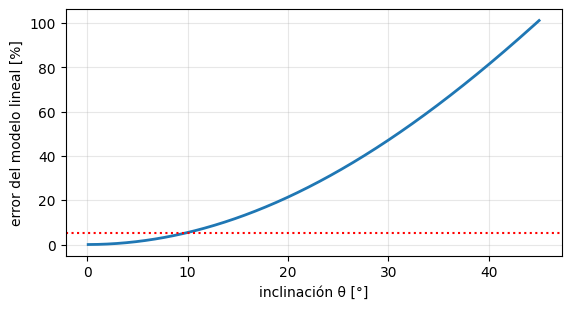

In [7]:
# Barrido: ¿en qué ángulo el error llega al 5 %?

d = np.linspace(0.1, 45, 900)
e = np.array([error_pct(x) for x in d])
print(f"5 %  de error a los {d[np.argmax(e > 5)]:.1f}°")
print(f"10 % de error a los {d[np.argmax(e > 10)]:.1f}°")

plt.figure(figsize=(6.4, 3.2))
plt.plot(d, e, lw=2); plt.axhline(5, ls=":", color="r")
plt.xlabel("inclinación θ [°]"); plt.ylabel("error del modelo lineal [%]")
plt.grid(alpha=.3); plt.show()

---
## 4. Cambie el robot y cambia el modelo

El día de la competencia el robot puede que cambie la masa por agregados y mejoras en el diseño mecánico y estructural. Analice qué efecto tiene esto.

In [8]:
for carga in [0.0, 0.15, 0.30, 0.60]:
    Am_c, _ = espacio_estados(Mb=Mb + carga)
    p_c = max(np.linalg.eigvals(Am_c).real)
    print(f"carga +{1000*carga:4.0f} g   ->   p = {p_c:6.3f} rad/s   "
          f"1/p = {1000/p_c:5.1f} ms   caída desde 3° = {1000*t_caida(3, Mb=Mb+carga):.0f} ms")

carga +   0 g   ->   p = 17.553 rad/s   1/p =  57.0 ms   caída desde 3° = 270 ms


carga + 150 g   ->   p = 19.140 rad/s   1/p =  52.2 ms   caída desde 3° = 254 ms
carga + 300 g   ->   p = 20.603 rad/s   1/p =  48.5 ms   caída desde 3° = 240 ms


carga + 600 g   ->   p = 23.250 rad/s   1/p =  43.0 ms   caída desde 3° = 222 ms


---
## 5. Tabla de resultados

Diligencie la tabla con los números que obtuvo. Este es el entregable de la sesión.

| Magnitud | Valor | Unidad |
|---|---:|---|
| Tiempo de caída desde θ₀ = 3°, robot vacío | 278.5 | ms |
| Polo inestable p, robot vacío | 17.257 | rad/s |
| Periodo de muestreo máximo Ts | 2.90 | ms |
| Ángulo con 5 % de error del modelo lineal | 9.1 | ° |
| Polo inestable p con 300 g de carga | 21.004 | rad/s |

*Nota: estos resultados corresponden a los parámetros genéricos del cuaderno (Mb = 0.600 kg, l = 0.070 m e Ib = 0.001 kg·m²), no necesariamente a las medidas del robot físico del equipo.*

---
## 6. Tres preguntas

Responda en dos o tres frases cada una.

**6.1** El ESP32-S3 corre a 240 MHz. Con el periodo de muestreo que calculó, ¿cuántos ciclos de reloj
tiene el microcontrolador para leer la IMU, estimar el ángulo, calcular el control y escribir el PWM?
¿Le parece suficiente o está "apretado" o "corta" esa frecuencia?

**6.2** El controlador PID (o LQR en próxima clase) que van a diseñar en la se calcula a partir del modelo
**lineal**. Según lo que midió en el paso 4, ¿en qué rango de inclinación puede confiar en ese
controlador? ¿Qué pasa si el robot recibe un golpe que lo saca de ese rango?

**6.3** Los valores de `Mb`, `l` e `Ib` que aparecen al principio son estimados y generales. Debe actualizarlos con los de su propio robot. Registre acá cómo los calculó o los obtuvo.

**6.1** Con el periodo de muestreo provisional `Ts ≈ 2.85 ms`, un microcontrolador a 240 MHz dispone de aproximadamente `240×10⁶ × 0.00285 ≈ 684 000 ciclos de reloj por muestra`. En principio parece suficiente para un PID o LQR sencillo, pero hay que medir el tiempo real de ejecución y considerar la lectura de la IMU, interrupciones y comunicaciones; además, el cálculo de `Ts` debe repetirse cuando se determine `Ib`.

**6.2** Con los parámetros actuales y `Ib` provisional, el error del modelo lineal alcanza el 5 % aproximadamente a los **9.6°** de inclinación respecto a la vertical. Este rango también es provisional; si un golpe saca al robot de él, las predicciones lineales pueden diferir de la dinámica real y el controlador puede no recuperar el equilibrio.

**6.3** Para este equipo se midieron `Mb = 0.750 kg`, `l = 0.062 m`, `mw = 0.050 kg` y `r = 0.033 m`. La inercia de una rueda se estimó suponiendo un disco macizo, dando `Iw = 2.7225×10⁻⁵ kg·m²` por rueda. El momento de inercia del cuerpo `Ib` sigue pendiente: el valor `0.001 kg·m²` que conserva el código es provisional, no medido; se debe reemplazar tras calcularlo con la distribución de masa de los componentes o estimarlo mediante un ensayo de oscilación física.


---
## Criterios de éxito

La actividad está lograda si al terminar la sesión su equipo puede:

1. Ejecutar el cuaderno completo sin errores.
2. Justificar de dónde sale cada uno de los dos coeficientes que completó en la matriz de estado.
3. Justificar por qué el periodo de muestreo del balancín no puede ser de 50 ms.
4. Nombrar el rango de inclinación en el que el modelo lineal es utilizable y decir qué observó
   fuera de ese rango.
5. Explicar por qué añadir carga al cuerpo cambia el polo inestable.

---
*Control Inteligente II – Ing. Jeisson Martínez Flórez*